# Linear algebra 8: The singular value decomposition

*Learning path: linear algebra, part 8 of 9.* [Index](README.md) · Previous: [Symmetric matrices](07-symmetric-matrices.ipynb) · Next: [Jordan form and the matrix exponential](09-jordan-and-matrix-exponential.ipynb)

Eigenvectors need a square matrix, and even then they may be missing or complex. The **singular value decomposition**
works for *every* matrix, of any shape: it says that every linear map is a rotation, then a stretch along
perpendicular axes, then another rotation. It is the workhorse of data science: it compresses images, finds the main
directions in data (principal component analysis), powers recommendation systems, and tells you how trustworthy the
solution of a linear system is.

**Who this is for.** You know the spectral theorem for symmetric matrices ([lesson 7](07-symmetric-matrices.ipynb))
and orthonormal bases ([lesson 5](05-orthogonality.ipynb)).

**What you will be able to do afterwards:**

1. explain $A = U\Sigma V^T$ geometrically: circles to ellipses;
2. compute the SVD from the eigenvectors of $A^TA$, by hand for small matrices;
3. read the rank, the four subspaces, the norm and the condition number from the SVD;
4. approximate a matrix by one of low rank, and find the main direction of a cloud of data points.

Plan about an hour and a half.

## 1. Every matrix turns circles into ellipses

In lesson 1 the matrix $[2\ 1;\ 1\ 2]$ turned the unit circle into an ellipse whose axes were its eigenvectors. That
was a symmetric matrix. Take a matrix that is not symmetric, $A = [3\ 0;\ 4\ 5]$. It still turns the unit circle into
an ellipse, but now the axes of the ellipse are *not* the images of eigenvectors. They are $\sigma_1u_1$ and
$\sigma_2u_2$: perpendicular directions $u_1, u_2$, stretched by the **singular values** $\sigma_1 \ge \sigma_2$. And
they are the images of two *perpendicular* vectors $v_1, v_2$ on the circle:

$$Av_1 = \sigma_1u_1, \qquad Av_2 = \sigma_2u_2.$$

In [1]:
A = [3 0; 4 5];
[U, S, V] = svd(A)

U = [  sqrt(10)/10, -3*sqrt(10)/10;
 3*sqrt(10)/10,    sqrt(10)/10]
S = [3*sqrt(5),       0;
         0, sqrt(5)]
V = [sqrt(2)/2, -sqrt(2)/2;
 sqrt(2)/2,  sqrt(2)/2]

> A = U*S*Vᵀ: the columns of V are orthonormal eigenvectors of AᵀA (the input directions), S holds the singular values 3*sqrt(5), sqrt(5) (square roots of the eigenvalues of AᵀA), and the columns of U are A*v/σ (the output directions), completed to an orthonormal basis. So A maps v_i to σ_i u_i: every matrix is a rotation, a stretch along the axes, and another rotation.

So $\sigma_1 = 3\sqrt5 \approx 6.71$ and $\sigma_2 = \sqrt5 \approx 2.24$, $v_1 = [1\ 1]/\sqrt2$, $u_1 = [1\ 3]/\sqrt{10}$.
All the equations $Av_i = \sigma_iu_i$ together read $AV = U\Sigma$, and since $V$ is orthogonal:

$$A = U\Sigma V^T.$$

Read from right to left: $V^T$ rotates the $v$'s onto the axes, $\Sigma$ stretches along the axes, $U$ rotates the axes
onto the $u$'s. The plot shows the circle, its image, and the two axes $\sigma_1u_1 = [3\ 9]/\sqrt2$ and
$\sigma_2u_2 = [-3\ 1]/\sqrt2$ (axes: the coordinates $x$ and $y$):

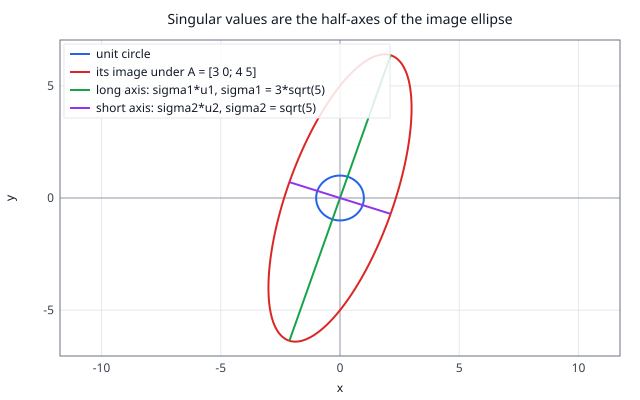

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
w = A*[cos(t); sin(t)];
p = show(parametric(cos(t), sin(t), t, 0, 2*pi), parametric(w(1), w(2), t, 0, 2*pi), parametric(3*s/sqrt(2), 9*s/sqrt(2), s, -1, 1), parametric(-3*s/sqrt(2), s/sqrt(2), s, -1, 1));
p = legend(p, "unit circle", "its image under A = [3 0; 4 5]", "long axis: sigma1*u1, sigma1 = 3*sqrt(5)", "short axis: sigma2*u2, sigma2 = sqrt(5)");
labels(title(p, "Singular values are the half-axes of the image ellipse"), "x", "y")

**Try this.** Check $Av_1 = \sigma_1u_1$ by hand: compute $A[1\ 1]$ and compare with $3\sqrt5\cdot[1\ 3]/\sqrt{10}\cdot\sqrt2$.

## 2. How to compute it

Multiply $A = U\Sigma V^T$ by its transpose: $A^TA = V\Sigma^TU^TU\Sigma V^T = V(\Sigma^T\Sigma)V^T$. That is the spectral
theorem for the symmetric matrix $A^TA$! So:

* the $v$'s are the orthonormal **eigenvectors of $A^TA$**;
* the $\sigma$'s are the square roots of its eigenvalues (which are $\ge 0$, since $A^TA$ is positive semidefinite);
* the $u$'s are $u_i = Av_i/\sigma_i$ (and they are eigenvectors of $AA^T$).

In [3]:
transpose(A)*A
eig(transpose(A)*A)
sqrt(45)

[25, 20;
 20, 25]
[5, 45]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

3*sqrt(5)

> `sqrt`: Square root; sqrt(-1) is the imaginary unit i.

Eigenvalues 45 and 5, so $\sigma = \sqrt{45} = 3\sqrt5$ and $\sqrt5$; eigenvectors $[1\ 1]$ and $[-1\ 1]$. Then
$u_1 = A[1\ 1]/(\sqrt2\cdot3\sqrt5) = [3\ 9]/(3\sqrt{10}) = [1\ 3]/\sqrt{10}$. Galileo gives an exact SVD when $A^TA$ has
rational eigenvalues, and a numeric one (by Jacobi rotations) otherwise:

In [4]:
svd([1 2; 3 4])

[5.46498570422, 0.365966190626]

> The singular values σ₁ ≥ σ₂ ≥ … ≥ 0 are the square roots of the eigenvalues of AᵀA (computed numerically). They measure how much A stretches: σ₁ is the largest stretch (the 2-norm of A), and the number of nonzero σ is the rank. [U, S, V] = svd(A) gives the full decomposition A = U*S*Vᵀ.

For a rectangular matrix, $\Sigma$ has the shape of $A$, with the singular values on its diagonal; $U$ is
$m\times m$ and $V$ is $n\times n$. The extra columns of $U$ complete an orthonormal basis:

In [5]:
[U, S, V] = svd([1 1; 1 1; 0 0])

U = [sqrt(2)/2,  sqrt(2)/2, 0;
 sqrt(2)/2, -sqrt(2)/2, 0;
         0,          0, 1]
S = [2, 0;
 0, 0;
 0, 0]
V = [sqrt(2)/2, -sqrt(2)/2;
 sqrt(2)/2,  sqrt(2)/2]

> A = U*S*Vᵀ: the columns of V are orthonormal eigenvectors of AᵀA (the input directions), S holds the singular values 2, 0 (square roots of the eigenvalues of AᵀA), and the columns of U are A*v/σ (the output directions), completed to an orthonormal basis. So A maps v_i to σ_i u_i: every matrix is a rotation, a stretch along the axes, and another rotation.

**Try this.** Find the singular values of $[2\ 0;\ 0\ {-3}]$ by hand. (Careful: singular values are never negative.
Where does the sign go?)

## 3. What the SVD tells you

**Rank.** The number of nonzero singular values. In the last example $\sigma = 2, 0$: rank 1.

**The four subspaces, with perpendicular bases.** With rank $r$: $v_1..v_r$ span the row space, $v_{r+1}..v_n$ the null
space, $u_1..u_r$ the column space, $u_{r+1}..u_m$ the left null space. Lesson 3 found these spaces; the SVD finds
*orthonormal* bases for all four at once, matched up so that $A$ sends each $v_i$ to $\sigma_iu_i$.

**Norm.** The largest stretch of any unit vector, $\max|Ax|/|x|$, is $\sigma_1$. That is the **2-norm** `norm(A)`.

**Condition number.** $\sigma_1/\sigma_n$ (for an invertible $n\times n$ matrix) measures how much solving $Ax = b$
can magnify relative errors in $b$: the ellipse is very thin, and a small change of $b$ in the thin direction needs a
large change of $x$. `cond` computes it.

In [6]:
norm(A)
cond(A)
cond([1 1; 1 1.0001])

6.708203932499369

> `norm`: Matrix norms: 2-norm (largest singular value, the default), 1-norm (largest column sum), inf-norm (largest row sum), Frobenius.

3

> Condition number = largest/smallest singular value = 3*sqrt(5)/sqrt(5). It bounds how much a relative error in b can grow in the solution of A x = b: you can lose about log10 of it in decimal digits.

40002.00007500187

> Condition number = largest/smallest singular value = 2.00005000125/0.00004999875. It bounds how much a relative error in b can grow in the solution of A x = b: you can lose about log10 of it in decimal digits.

$[1\ 1;\ 1\ 1.0001]$ is nearly singular: its condition number is about 40000, so you may lose 4 or 5 of your 16
digits when solving with it.

**Try this.** Why does an orthogonal matrix $Q$ have condition number 1? (What does it do to the unit circle?)

## 4. Low-rank approximation: compressing a picture

Write out $A = U\Sigma V^T$ column by column: it is a sum of rank-one pieces,

$$A = \sigma_1u_1v_1^T + \sigma_2u_2v_2^T + \cdots + \sigma_ru_rv_r^T,$$

in order of importance. Keeping the first $k$ terms gives $A_k$, and the **Eckart–Young theorem** says that no matrix of
rank $k$ is closer to $A$: the error $\|A - A_k\|$ is exactly $\sigma_{k+1}$.

Here is a tiny black-and-white picture, a frame with a square in the middle (1 = black):

In [7]:
M = [1 1 1 1 1 1; 1 0 0 0 0 1; 1 0 1 1 0 1; 1 0 1 1 0 1; 1 0 0 0 0 1; 1 1 1 1 1 1];
svd(M)

[4.49395920743, 1.60387547161, 1.10991626417, 0, 0, 0]

> The singular values σ₁ ≥ σ₂ ≥ … ≥ 0 are the square roots of the eigenvalues of AᵀA (computed numerically). They measure how much A stretches: σ₁ is the largest stretch (the 2-norm of A), and the number of nonzero σ is the rank. [U, S, V] = svd(A) gives the full decomposition A = U*S*Vᵀ.

Rank 3, with singular values about $4.49, 1.60, 1.11$. The best rank-1 picture, rounded to one decimal, is a smooth blur;
rank 2 already has the right shape, and rounding it to 0 and 1 recovers the picture exactly:

In [8]:
[U, S, V] = svd(M);
A1 = S(1, 1)*column(U, 1)*transpose(column(V, 1));
A2 = A1 + S(2, 2)*column(U, 2)*transpose(column(V, 2));
eval(round(10*A1)/10)
round(A2)
norm(M - A1)
norm(M - A2)

[1.2, 0.5, 1.0, 1.0, 0.5, 1.2;
 0.5, 0.2, 0.4, 0.4, 0.2, 0.5;
 1.0, 0.4, 0.8, 0.8, 0.4, 1.0;
 1.0, 0.4, 0.8, 0.8, 0.4, 1.0;
 0.5, 0.2, 0.4, 0.4, 0.2, 0.5;
 1.2, 0.5, 1.0, 1.0, 0.5, 1.2]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

[1, 1, 1, 1, 1, 1;
 1, 0, 0, 0, 0, 1;
 1, 0, 1, 1, 0, 1;
 1, 0, 1, 1, 0, 1;
 1, 0, 0, 0, 0, 1;
 1, 1, 1, 1, 1, 1]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

1.603875471609675

> `norm`: Matrix norms: 2-norm (largest singular value, the default), 1-norm (largest column sum), inf-norm (largest row sum), Frobenius.

1.1099162641747422

> `norm`: Matrix norms: 2-norm (largest singular value, the default), 1-norm (largest column sum), inf-norm (largest row sum), Frobenius.

The errors are $\sigma_2$ and $\sigma_3$, as Eckart–Young promises. A real photo of $1000\times1000$ pixels needs a
million numbers; its rank-50 approximation needs $50\cdot(1000 + 1000 + 1) \approx 100{,}000$ and often looks almost
the same, because the singular values of natural images drop fast.

**Try this.** How many numbers does $A_k$ need for an $m\times n$ matrix? For which $k$ does it stop saving space?

## 5. Principal components: the main direction of data

Six students' scores on two quizzes, one row per student:

In [9]:
D = [1 2; 2 3; 3 3; 4 5; 5 5; 6 7];
ones(1, 6)*D/6

[7/2, 25/6]

Subtract the averages, $[7/2\ \ 25/6]$, so the cloud is centered at 0. The first right singular vector $v_1$ of the
centered data is the direction in which the points spread the most: the **first principal component**. The singular
value $\sigma_1$ measures that spread ($\sigma_1^2/(n-1)$ is the variance along $v_1$), and $\sigma_2$ the spread across.

In [10]:
C = D - ones(6, 1)*[7/2 25/6];
[U, S, V] = svd(C);
column(V, 1)
svd(C)

[0.714212118009;
 0.699929318209]

> `column`: Column k of a matrix (counting from 1), as a column vector.

[5.80258850226, 0.814432321784]

> The singular values σ₁ ≥ σ₂ ≥ … ≥ 0 are the square roots of the eigenvalues of AᵀA (computed numerically). They measure how much A stretches: σ₁ is the largest stretch (the 2-norm of A), and the number of nonzero σ is the rank. [U, S, V] = svd(A) gives the full decomposition A = U*S*Vᵀ.

$v_1 \approx [0.714\ \ 0.700]$: slope $0.700/0.714 \approx 0.98$. The spread along it ($\sigma_1 \approx 5.80$) is about
seven times the spread across ($\sigma_2 \approx 0.81$): the two quizzes mostly measure one thing. The plot shows the
scores and the principal direction through the average point (axes: the two quiz scores):

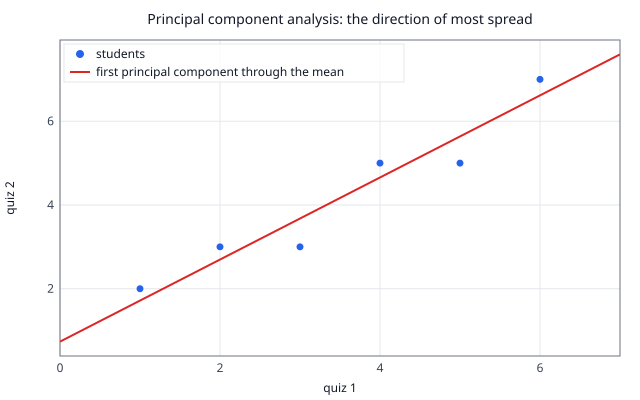

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
p = show(scatter(D, [q1 q2]), plot(25/6 + 0.98*(q1 - 7/2), q1, 0, 7));
p = legend(p, "students", "first principal component through the mean");
labels(title(p, "Principal component analysis: the direction of most spread"), "quiz 1", "quiz 2")

The principal component line is not the least squares line of lesson 5: least squares minimizes vertical distances
(errors in $y$ only), PCA minimizes *perpendicular* distances (both scores are equally uncertain). With 1000 features
instead of 2, the first few principal components are how data scientists see the shape of the data.

**Try this.** Which line does PCA give for the three points $(0, 0)$, $(1, 1)$, $(2, 2)$, and what is $\sigma_2$? Think
before computing.

## Exercises

1. **By hand.** Find the SVD of $A = [1\ 1;\ 0\ 0]$: eigenvectors of $A^TA$, singular values, $u_1$. Which
   vector spans the null space?
2. **Symmetric matrices.** For a symmetric positive definite matrix the SVD is the spectral decomposition. What changes
   for a symmetric matrix with a negative eigenvalue, such as $[1\ 2;\ 2\ 1]$?
3. **Norm and inverse.** If $A$ is invertible with singular values $\sigma_i$, what are the singular values of
   $A^{-1}$? What is $\|A^{-1}\|$?
4. **Rank one.** The matrix $[1\ 2\ 3;\ 2\ 4\ 6]$ has rank 1. Write it as $\sigma_1u_1v_1^T$.
5. **Compression.** For the picture `M`, check that $A_3 = M$ (up to rounding) and that $\|M - A_k\| = \sigma_{k+1}$
   for $k = 1, 2$.

## Hints and answers

* **Section 1, Try this.** $A[1\ 1] = [3\ 9]$, and $3\sqrt5\cdot[1\ 3]/\sqrt{10}\cdot\sqrt2 = 3\cdot[1\ 3] = [3\ 9]$.
* **Section 2, Try this.** $\sigma = 3$ and $2$. The sign goes into $U$ (or $V$): for $\sigma_1 = 3$, $v_1 = [0\ 1]$ while $u_1 = [0\ {-1}]$.
* **Section 3, Try this.** $Q$ turns the unit circle into the unit circle: all singular values are 1.
* **Section 4, Try this.** $k(m + n + 1)$ numbers instead of $mn$: it saves space while $k < mn/(m + n + 1)$, for a
  $1000\times1000$ matrix about $k < 500$.
* **Section 5, Try this.** The line $y = x$ through the points, with $\sigma_2 = 0$: no spread across.
* **Exercise 1.** $A^TA = [1\ 1;\ 1\ 1]$, eigenvalues 2 and 0, $v_1 = [1\ 1]/\sqrt2$, $\sigma_1 = \sqrt2$,
  $u_1 = [1\ 0]$. The null space is spanned by $v_2 = [-1\ 1]/\sqrt2$.
* **Exercise 2.** The singular values are the absolute values of the eigenvalues, 3 and 1; the sign of $-1$ moves into
  $U$, so $U \ne V$.
* **Exercise 3.** $A^{-1} = V\Sigma^{-1}U^T$: singular values $1/\sigma_i$, and $\|A^{-1}\| = 1/\sigma_n$. So
  $\text{cond}(A) = \|A\|\,\|A^{-1}\|$.
* **Exercise 4.** $u_1 = [1\ 2]/\sqrt5$, $v_1 = [1\ 2\ 3]/\sqrt{14}$, $\sigma_1 = \sqrt{70}$.
* **Exercise 5.** Add `S(3, 3)*column(U, 3)*transpose(column(V, 3))` to `A2` and compare with `M`.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), chapter 7.
2. G. Strang, *Linear Algebra and Learning from Data*, Wellesley-Cambridge Press (2019), sections I.8 and I.9.
3. C. Eckart and G. Young, "The approximation of one matrix by another of lower rank", *Psychometrika* 1 (1936)
   211–218.
4. G. W. Stewart, "On the early history of the singular value decomposition", *SIAM Review* 35 (1993) 551–566.